# Landmine Victims in Colombia: A Reproducible Data Workflow

**Author:** Travis Carlson
**Dataset:** *Situación Víctimas Minas Antipersonal en Colombia*, published by the Presidencia de la República de Colombia on the national open data portal (CC BY-SA 4.0)

This notebook builds a reproducible workflow for Colombia's official register of people killed or injured by antipersonnel mines, improvised devices that act like them, and unexploded ordnance, from 1990 to 2023 (12,390 records, one per victim). It loads the published file unchanged, cleans it through a documented pipeline, explores who was harmed, where and when, and charts the main patterns. The cleaned table is the base for later projects on humanitarian mine action.

## 1. Setup

Libraries, file locations, the provenance of the raw file, and one chart style used throughout. The workflow uses only Python, NumPy, Pandas, Matplotlib and Seaborn.

In [1]:
import hashlib
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)

# Files (the raw file sits in the same folder as this notebook)
DATA_FILE = Path("victimas_minas_antipersonal.csv")
CLEAN_FILE = Path("victimas_minas_antipersonal_clean.csv")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

# Provenance of the raw file
SOURCE_PAGE = ("https://www.datos.gov.co/Inclusi-n-Social-y-Reconciliaci-n/"
               "Situaci-n-V-ctimas-Minas-Antipersonal-en-Colombia/yhxn-eqqw")
DOWNLOAD_URL = "https://www.datos.gov.co/api/views/yhxn-eqqw/rows.csv?accessType=DOWNLOAD"
DOWNLOADED_ON = "2026-10-18"
EXPECTED_SHA256 = "6ac13df53d0024bc9d96f8b48d7622934b5bd1a334d40cf4155bf4cea804a84d"

# Chart style: light surface, quiet grid, and one fixed colour per group in every chart
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE = "#e1e0d9", "#c3c2b7"
GROUP_COLOURS = {"Civilian": "#2a78d6", "Security forces": "#eb6834"}
NOT_RECORDED = "#c3c2b7"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": BASELINE, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 1, "grid.linestyle": "-",
    "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "font.size": 10, "lines.linewidth": 2, "legend.frameon": False,
})

for name, module in [("pandas", pd), ("numpy", np), ("matplotlib", matplotlib), ("seaborn", sns)]:
    print(f"{name:<10} {module.__version__}")

pandas     3.0.6
numpy      2.5.4
matplotlib 3.11.2
seaborn    0.13.2


## 2. Ingestion

The raw file is a snapshot of the portal's CSV export, kept unchanged next to this notebook. Its SHA-256 checksum is compared with the one recorded when it was downloaded, so anyone rerunning the notebook can confirm they are using the same data.

In [2]:
def file_sha256(path):
    """Return the SHA-256 checksum of a file, reading it in 1 MB chunks.

    Used to confirm that the raw file is the same snapshot recorded in the README.
    A different checksum means a newer download or a changed file.
    """
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


checksum = file_sha256(DATA_FILE)
print(f"Source page:   {SOURCE_PAGE}")
print(f"Downloaded on: {DOWNLOADED_ON}")
print(f"SHA-256:       {checksum}")
if checksum == EXPECTED_SHA256:
    print("Checksum matches the recorded snapshot.")
else:
    print("WARNING: checksum differs from the recorded snapshot; results may not match the report.")

df_raw = pd.read_csv(DATA_FILE, encoding="utf-8")
print(f"\nLoaded {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
df_raw.head()

Source page:   https://www.datos.gov.co/Inclusi-n-Social-y-Reconciliaci-n/Situaci-n-V-ctimas-Minas-Antipersonal-en-Colombia/yhxn-eqqw
Downloaded on: 2026-10-18
SHA-256:       6ac13df53d0024bc9d96f8b48d7622934b5bd1a334d40cf4155bf4cea804a84d
Checksum matches the recorded snapshot.

Loaded 12,390 rows x 18 columns


,departamento,codigodanedepartamento,municipio,codigodanemunicipio,tipoarea,sitio,ano,mes,rangoedad,grupoetnico,condicion,estado,genero,latitudcabecera,longitudcabecera,tipoevento,Ubicación,Actividad
0,ANTIOQUIA,5,GRANADA,5313,Rural,Sin información,2006,1,Mayor de 18 años,no,Civil,Hombre,Herido,6.143703,-75.185183,Sin informacion,"(6.143703, -75.185183)","Pasando, estando cerca"
1,CAQUETA,18,MONTAÑITA,18410,Rural,Sin información,2009,12,Mayor de 18 años,no,Civil,Hombre,Herido,1.494944,-75.463090,Sin informacion,"(1.49494421255, -75.4630895064)",Erradicador manual - PCI
2,BOLIVAR,13,ARENAL,13042,Rural,Sin información,2023,2,Mayor de 18 años,no,Civil,Hombre,Herido,8.471395,-73.942728,Campo,"(8.47139540671, -73.9427278067)",Agricultura
3,BOLIVAR,13,ARENAL,13042,Rural,Sin información,2023,2,Mayor de 18 años,no,Civil,Hombre,Herido,8.471395,-73.942728,Campo,"(8.47139540671, -73.9427278067)",Agricultura
4,PUTUMAYO,86,PUERTO ASÍS,86568,Rural,Sin información,2008,4,Mayor de 18 años,no,Civil,Hombre,Muerto,0.502569,-76.498180,Sin informacion,"(0.502569, -76.49818)",Erradicador manual - PCI


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 12390 entries, 0 to 12389
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   departamento            12390 non-null  str    
 1   codigodanedepartamento  12390 non-null  int64  
 2   municipio               12390 non-null  str    
 3   codigodanemunicipio     12390 non-null  int64  
 4   tipoarea                12390 non-null  str    
 5   sitio                   12390 non-null  str    
 6   ano                     12390 non-null  int64  
 7   mes                     12390 non-null  int64  
 8   rangoedad               12390 non-null  str    
 9   grupoetnico             12390 non-null  str    
 10  condicion               12390 non-null  str    
 11  estado                  12390 non-null  str    
 12  genero                  12390 non-null  str    
 13  latitudcabecera         12390 non-null  float64
 14  longitudcabecera        12390 non-null  float64
 

## 3. Cleaning

A first look at the raw file shows six problems. Each one gets its own small function, and the functions run in order as a pipeline. Every step returns a new table, so the raw data is never changed, and the pipeline logs the table's size and missing cells after each step.

| Step | Function | Problem in the raw file | Why it matters |
|---|---|---|---|
| 1 | `fix_column_labels` | Spanish column names; `estado` holds sex, `genero` holds killed or injured, and `tipoevento` holds the type of place | Any analysis by the published labels would be wrong |
| 2 | `drop_location_detail` | Free-text site names (some are street addresses) and municipal-seat coordinates | Not needed at municipality level, and they add privacy risk |
| 3 | `standardise_missing` | "No information" written as `Sin información`, `Sin Información` or `Sin informacion`, plus stray spaces | Left as text, missing values would be counted as a category |
| 4 | `standardise_codes` | DANE codes read as numbers, losing their leading zero; some municipality names repeat across departments | The zero-padded code is the reliable key, not the name |
| 5 | `translate_categories` | Spanish categories, with several spellings for the same activity | One English data dictionary makes every merge explicit |
| 6 | `add_time_fields` | Year and month stored in separate columns | A single date and a decade label make time views simple |

One thing the pipeline deliberately does **not** do is delete repeated rows; section 3.4 explains why.

### 3.1 Data dictionary

Published column names and categories, mapped to English. Category keys are written in lower case without accents, because the matching function compares values after removing case, accents and extra spaces.

Two translations rest on assumptions: the ethnic-group value `no` is read as "none or not recorded", and the three crop-eradication activities (manual eradicator, crop eradication, police eradication) and the two security-force activities are merged.

In [4]:
# Published column -> English column. Three published labels do not match their values.
COLUMN_MAP = {
    "departamento": "department",
    "codigodanedepartamento": "department_code",
    "municipio": "municipality",
    "codigodanemunicipio": "municipality_code",
    "tipoarea": "area_type",
    "sitio": "site",
    "ano": "year",
    "mes": "month",
    "rangoedad": "age_group",
    "grupoetnico": "ethnic_group",
    "condicion": "condition",
    "estado": "sex",            # published label means 'state'; values are Hombre/Mujer
    "genero": "outcome",        # published label means 'gender'; values are Herido/Muerto
    "latitudcabecera": "seat_latitude",
    "longitudcabecera": "seat_longitude",
    "tipoevento": "place_type",  # published label means 'event type'; values are places
    "Ubicación": "seat_location",
    "Actividad": "activity",
}

LOCATION_DETAIL = ["site", "seat_latitude", "seat_longitude", "seat_location"]
MISSING_CODES = {"sin informacion"}

# Spanish category (normalised) -> English label
CATEGORY_MAP = {
    "area_type": {"rural": "Rural", "urbana": "Urban"},
    "age_group": {"mayor de 18 anos": "Adult (18+)", "menor de 18 anos": "Minor (under 18)"},
    "ethnic_group": {"no": "None or not recorded", "indigena": "Indigenous",
                     "afrodescendiente": "Afro-descendant"},
    "condition": {"civil": "Civilian", "fuerza publica": "Security forces"},
    "sex": {"hombre": "Male", "mujer": "Female"},
    "outcome": {"herido": "Injured", "muerto": "Killed"},
    "place_type": {
        "caminos": "Paths", "campo": "Open field", "cerros": "Hills", "fincas": "Farms",
        "en cerca a edificio residencial": "Near a residential building",
        "en sobre cerca rivera de un rio": "On or near a riverbank",
        "sendero": "Trail", "carretera": "Road", "campamentos ilegales": "Illegal camps",
        "canos": "Streams", "oleoductos": "Oil pipelines",
        "viviendas abandonadas": "Abandoned houses", "quebradas": "Creeks",
        "infra torres electricas": "Power-line towers", "puentes": "Bridges",
        "borde de la carretera": "Roadside",
        "en cerca instalacion militar": "Near a military installation",
        "en cerca edificio gubernamental": "Near a government building",
        "infraestructura de comunicaciones": "Communications infrastructure",
        "escuelas": "Schools", "centros deportivos recreacion": "Sports and recreation centres",
        "infra gaseoducto": "Gas pipeline", "centro de salud": "Health centre",
    },
    "activity": {
        "fuerza publica": "Security-force duties",
        "actividades fuerza publica": "Security-force duties",
        "pasando, estando cerca": "Passing by or nearby",
        "agricultura": "Farming",
        "erradicador manual - pci": "Illicit-crop eradication",
        "erradicacion de cultivos ilicitos": "Illicit-crop eradication",
        "erradicacion - ponal": "Illicit-crop eradication",
        "manipulacion": "Handling the device",
        "transito por via usual": "Travelling on a usual route",
        "recogiendo comida, agua o madera": "Gathering food, water or wood",
        "jugando": "Playing",
        "cuidado de animales": "Tending animals",
        "otra": "Other",
        "transito por trocha atajo": "Travelling on a trail or shortcut",
        "trabajos de casa": "Household work",
        "caza, pesca": "Hunting or fishing",
        "mantenimiento de infraestructura": "Infrastructure maintenance",
        "viajando": "Travelling",
        "labores de desminado": "Demining work",
        "labores de rescate": "Rescue work",
    },
}
print(f"{len(COLUMN_MAP)} columns mapped; "
      f"{sum(len(m) for m in CATEGORY_MAP.values())} category spellings translated")

18 columns mapped; 56 category spellings translated


### 3.2 Cleaning functions

In [5]:
def normalise_text(value):
    """Lower-case a text value, remove accents and collapse repeated spaces.

    Lets the pipeline compare spellings that differ only in case, accents or
    spacing, such as 'Sin Información' and 'Sin informacion'. Missing values
    are returned unchanged.
    """
    if pd.isna(value):
        return value
    text = unicodedata.normalize("NFKD", str(value))
    text = "".join(ch for ch in text if not unicodedata.combining(ch))
    return " ".join(text.lower().split())


def fix_column_labels(df):
    """Rename the published Spanish columns to English and correct three mislabelled ones.

    The published labels `estado`, `genero` and `tipoevento` do not describe their
    values: `estado` holds sex (Hombre/Mujer), `genero` holds the outcome
    (Herido/Muerto) and `tipoevento` holds the type of place. The value sets are
    checked before renaming, so the step fails loudly if a later release fixes
    the labels and this mapping needs revisiting.
    """
    missing = set(COLUMN_MAP) - set(df.columns)
    assert not missing, f"Columns not found in the raw file: {missing}"
    sex_values = set(df["estado"].dropna().map(normalise_text))
    outcome_values = set(df["genero"].dropna().map(normalise_text))
    assert sex_values <= {"hombre", "mujer", "sin informacion"}, sex_values
    assert outcome_values <= {"herido", "muerto"}, outcome_values
    return df.rename(columns=COLUMN_MAP)


def drop_location_detail(df, columns=LOCATION_DETAIL):
    """Drop free-text site names and the municipal-seat coordinates.

    The analysis works at municipality level, which the DANE municipality code
    already identifies. Some site names are street addresses, so removing these
    columns also keeps location detail out of every output.
    """
    return df.drop(columns=list(columns))


def standardise_missing(df):
    """Tidy text values and turn the disguised 'no information' code into missing values.

    The raw file writes 'no information' as 'Sin información', 'Sin Información'
    or 'Sin informacion'. Left as text, these would be counted as a category in
    every table and chart. Leading, trailing and repeated spaces are also removed.
    """
    out = df.copy()
    for column in out.columns:
        if not (out[column].dtype == object or pd.api.types.is_string_dtype(out[column])):
            continue
        tidy = out[column].map(lambda v: v if pd.isna(v) else " ".join(str(v).split()))
        out[column] = tidy.mask(tidy.map(normalise_text).isin(MISSING_CODES))
    return out


def standardise_codes(df):
    """Store DANE codes as zero-padded text and add an unambiguous municipality label.

    DANE codes are identifiers, not quantities: department codes have two digits
    and municipality codes five (for example 05 is Antioquia and 05313 is Granada,
    Antioquia). Read as numbers they lose the leading zero. Some municipality names
    are used in more than one department, so the code, not the name, is the key.
    """
    out = df.copy()
    out["department_code"] = out["department_code"].astype(int).astype(str).str.zfill(2)
    out["municipality_code"] = out["municipality_code"].astype(int).astype(str).str.zfill(5)
    out["municipality_label"] = out["municipality"] + " (" + out["department"] + ")"
    return out


def translate_categories(df, category_map=None):
    """Translate Spanish categories to English using the data dictionary.

    Values are matched after normalising case, accents and spaces, so spelling
    variants collapse to one English label. Any value missing from the dictionary
    raises an error instead of passing through untranslated.
    """
    category_map = CATEGORY_MAP if category_map is None else category_map
    out = df.copy()
    for column, mapping in category_map.items():
        keys = out[column].map(normalise_text)
        unmapped = sorted(set(keys.dropna()) - set(mapping))
        assert not unmapped, f"{column}: no translation for {unmapped}"
        out[column] = keys.map(mapping)
    return out


def add_time_fields(df):
    """Add a first-of-month date and a decade label built from year and month.

    The raw file stores year and month as separate numbers. One date column makes
    time series straightforward, and decades give a coarser view.
    """
    out = df.copy()
    out["year_month"] = pd.to_datetime(out[["year", "month"]].assign(day=1))
    out["decade"] = (out["year"] // 10 * 10).astype(str) + "s"
    return out


def missing_cells(df):
    """Count the missing cells in a DataFrame."""
    return int(df.isna().sum().sum())


def run_pipeline(df, steps):
    """Apply cleaning steps in order and log the table after each one.

    Each step takes a DataFrame and returns a new one, so the raw data is never
    changed in place. Returns the cleaned DataFrame and a log of rows, columns
    and missing cells after every step.
    """
    log = [{"step": "raw file", "rows": len(df), "columns": df.shape[1],
            "missing cells": missing_cells(df)}]
    current = df
    for step in steps:
        current = step(current)
        log.append({"step": step.__name__, "rows": len(current), "columns": current.shape[1],
                    "missing cells": missing_cells(current)})
    return current, pd.DataFrame(log)

### 3.3 Run the pipeline and check the result

In [6]:
PIPELINE = [fix_column_labels, drop_location_detail, standardise_missing,
            standardise_codes, translate_categories, add_time_fields]

df, cleaning_log = run_pipeline(df_raw, PIPELINE)
cleaning_log

,step,rows,columns,missing cells
0,raw file,12390,18,0
1,fix_column_labels,12390,18,0
2,drop_location_detail,12390,14,0
3,standardise_missing,12390,14,13508
4,standardise_codes,12390,15,13508
5,translate_categories,12390,15,13508
6,add_time_fields,12390,17,13508


In [7]:
def check_clean(df, raw_rows):
    """Assert the cleaned table's structure and categories, then print a short report.

    Checks that cleaning kept every victim, that years, months and DANE codes are
    valid, that each municipality code sits inside its department, and that every
    category is one of the data dictionary's English labels.
    """
    assert len(df) == raw_rows, "Cleaning must not add or remove victims"
    assert df["month"].between(1, 12).all(), "Months must run from 1 to 12"
    assert df["department_code"].str.fullmatch(r"\d{2}").all()
    assert df["municipality_code"].str.fullmatch(r"\d{5}").all()
    assert (df["municipality_code"].str[:2] == df["department_code"]).all()
    for column, mapping in CATEGORY_MAP.items():
        assert set(df[column].dropna()) <= set(mapping.values()), column
    shared = df.groupby("municipality")["municipality_code"].nunique()
    print(f"All checks passed: {len(df):,} victims, {df['year'].min()}–{df['year'].max()}, "
          f"{df['department_code'].nunique()} departments, "
          f"{df['municipality_code'].nunique()} municipalities.")
    print(f"{(shared > 1).sum()} municipality names belong to more than one department, "
          "which is why the code is the key.")


check_clean(df, len(df_raw))
df.head()

All checks passed: 12,390 victims, 1990–2023, 32 departments, 519 municipalities.
21 municipality names belong to more than one department, which is why the code is the key.


,department,department_code,municipality,municipality_code,area_type,year,month,age_group,ethnic_group,condition,sex,outcome,place_type,activity,municipality_label,year_month,decade
0,ANTIOQUIA,05,GRANADA,05313,Rural,2006,1,Adult (18+),None or not recorded,Civilian,Male,Injured,NaN,Passing by or nearby,GRANADA (ANTIOQUIA),2006-01-01,2000s
1,CAQUETA,18,MONTAÑITA,18410,Rural,2009,12,Adult (18+),None or not recorded,Civilian,Male,Injured,NaN,Illicit-crop eradication,MONTAÑITA (CAQUETA),2009-12-01,2000s
2,BOLIVAR,13,ARENAL,13042,Rural,2023,2,Adult (18+),None or not recorded,Civilian,Male,Injured,Open field,Farming,ARENAL (BOLIVAR),2023-02-01,2020s
3,BOLIVAR,13,ARENAL,13042,Rural,2023,2,Adult (18+),None or not recorded,Civilian,Male,Injured,Open field,Farming,ARENAL (BOLIVAR),2023-02-01,2020s
4,PUTUMAYO,86,PUERTO ASÍS,86568,Rural,2008,4,Adult (18+),None or not recorded,Civilian,Male,Killed,NaN,Illicit-crop eradication,PUERTO ASÍS (PUTUMAYO),2008-04-01,2000s


### 3.4 Repeated rows are kept, not deleted

Many rows repeat another row exactly. The file has no victim or event identifier, so two people hurt in the same accident, in the same municipality and month, with the same age group, sex and outcome, produce identical rows. Deleting "duplicates" would therefore delete real victims. The table below shows how many rows a blanket de-duplication would remove from each group.

In [8]:
def repeated_row_impact(raw, cleaned, by):
    """Show how many rows per group a blanket de-duplication of the raw file would remove.

    A row counts as repeated when it matches an earlier row in every raw column.
    `cleaned` supplies the English group labels; it must keep the raw row order.
    """
    repeated = raw.duplicated(keep="first").to_numpy()
    impact = (cleaned.assign(repeated=repeated)
                     .groupby(by)["repeated"].agg(rows="size", repeated="sum"))
    impact["% that would be deleted"] = (impact["repeated"] / impact["rows"] * 100).round(1)
    return impact


repeats = df_raw.duplicated(keep="first")
print(f"{repeats.sum():,} of {len(df_raw):,} rows ({repeats.mean():.0%}) repeat an earlier row exactly.")
repeated_row_impact(df_raw, df, "condition")

3,858 of 12,390 rows (31%) repeat an earlier row exactly.


,rows,repeated,% that would be deleted
condition,,,
Civilian,5022,1105,22.0
Security forces,7368,2753,37.4


In [9]:
# "\n" line endings on every operating system, so a rerun on Windows writes the same file
df.to_csv(CLEAN_FILE, index=False, lineterminator="\n")
print(f"Saved {CLEAN_FILE} ({len(df):,} rows x {df.shape[1]} columns); licence: CC BY-SA 4.0, as the source")

Saved victimas_minas_antipersonal_clean.csv (12,390 rows x 17 columns); licence: CC BY-SA 4.0, as the source


## 4. Exploratory data analysis

Four reusable functions: a column profile, grouped counts with shares, the share killed by group, and yearly counts by condition (used for a correlation check). Results are reported as national or department totals only.

In [10]:
def profile_columns(df):
    """Summarise each column: data type, missing values, distinct values and an example."""
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing": df.isna().sum(),
        "missing %": (df.isna().mean() * 100).round(1),
        "distinct": df.nunique(),
        "example": df.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None),
    })


def count_and_share(df, by):
    """Count victims by one or more columns and give each group's share of the total.

    Missing values are kept as their own group, so unrecorded categories stay visible.
    """
    counts = df.groupby(by, dropna=False).size().rename("victims").reset_index()
    counts["share %"] = (counts["victims"] / counts["victims"].sum() * 100).round(1)
    return counts.sort_values("victims", ascending=False, ignore_index=True)


def share_killed(df, by):
    """Return the number of victims, the number killed and the percentage killed per group."""
    table = df.assign(killed=df["outcome"].eq("Killed")).groupby(by).agg(
        victims=("outcome", "size"), killed=("killed", "sum"))
    table["killed %"] = (table["killed"] / table["victims"] * 100).round(1)
    return table


def yearly_counts(df):
    """Return victims per year, with one column per condition (civilian, security forces)."""
    return df.groupby(["year", "condition"]).size().unstack(fill_value=0)

In [11]:
profile_columns(df)

,dtype,missing,missing %,distinct,example
department,str,0,0.0,32,ANTIOQUIA
department_code,str,0,0.0,32,05
municipality,str,0,0.0,498,GRANADA
municipality_code,str,0,0.0,519,05313
area_type,str,0,0.0,2,Rural
year,int64,0,0.0,34,2006
month,int64,0,0.0,12,1
age_group,str,0,0.0,2,Adult (18+)
ethnic_group,str,0,0.0,3,None or not recorded
condition,str,0,0.0,2,Civilian


### 4.1 Summary statistics

In [12]:
yearly = yearly_counts(df)
yearly["Total"] = yearly.sum(axis=1)
print("Victims per year, 1990–2023:")
yearly.describe().round(1)

Victims per year, 1990–2023:


condition,Civilian,Security forces,Total
count,34.0,34.0,34.0
mean,147.7,216.7,364.4
std,128.9,234.0,357.4
min,4.0,17.0,23.0
25%,43.2,49.8,91.5
50%,92.0,91.0,166.5
75%,281.2,336.0,620.5
max,434.0,790.0,1224.0


In [13]:
for column in ["condition", "outcome", "age_group", "sex", "area_type", "ethnic_group"]:
    display(count_and_share(df, column))

,condition,victims,share %
0,Security forces,7368,59.5
1,Civilian,5022,40.5


,outcome,victims,share %
0,Injured,10038,81.0
1,Killed,2352,19.0


,age_group,victims,share %
0,Adult (18+),11113,89.7
1,Minor (under 18),1277,10.3


,sex,victims,share %
0,Male,11677,94.2
1,Female,673,5.4
2,NaN,40,0.3


,area_type,victims,share %
0,Rural,12142,98.0
1,Urban,248,2.0


,ethnic_group,victims,share %
0,None or not recorded,11772,95.0
1,Indigenous,488,3.9
2,Afro-descendant,130,1.0


### 4.2 Grouped and filtered views

In [14]:
print("Share killed, by condition:")
display(share_killed(df, "condition"))
print("Share killed, by condition and age group:")
display(share_killed(df, ["condition", "age_group"]))

Share killed, by condition:


,victims,killed,killed %
condition,,,
Civilian,5022,894,17.8
Security forces,7368,1458,19.8


Share killed, by condition and age group:


victims  killed  killed %
condition       age_group                                  
Civilian        Adult (18+)          3745     635      17.0
                Minor (under 18)     1277     259      20.3
Security forces Adult (18+)          7368    1458      19.8

In [15]:
civilians = df[df["condition"] == "Civilian"]
print(f"Civilian victims: {len(civilians):,}; "
      f"activity not recorded for {civilians['activity'].isna().mean():.0%} of them.")
count_and_share(civilians, "activity").head(12)

Civilian victims: 5,022; activity not recorded for 40% of them.


,activity,victims,share %
0,NaN,2002,39.9
1,Passing by or nearby,1109,22.1
2,Illicit-crop eradication,432,8.6
3,Farming,369,7.3
4,Handling the device,191,3.8
5,Travelling on a usual route,187,3.7
6,"Gathering food, water or wood",183,3.6
7,Playing,136,2.7
8,Tending animals,105,2.1
9,Other,98,2.0


In [16]:
departments = df.groupby(["department", "condition"]).size().unstack(fill_value=0)
departments["Total"] = departments.sum(axis=1)
departments["Civilian %"] = (departments["Civilian"] / departments["Total"] * 100).round(1)
departments["Share of all victims %"] = (departments["Total"] / len(df) * 100).round(1)
departments.sort_values("Total", ascending=False).head(10)

condition,Civilian,Security forces,Total,Civilian %,Share of all victims %
department,,,,,
ANTIOQUIA,1226,1432,2658,46.1,21.5
META,427,725,1152,37.1,9.3
NARIÑO,748,374,1122,66.7,9.1
NORTE DE SANTANDER,299,671,970,30.8,7.8
CAQUETA,222,726,948,23.4,7.7
CAUCA,315,357,672,46.9,5.4
ARAUCA,231,425,656,35.2,5.3
BOLIVAR,238,409,647,36.8,5.2
TOLIMA,83,456,539,15.4,4.4


In [17]:
by_decade = df.groupby(["decade", "condition"]).size().unstack(fill_value=0)
by_decade["Civilian %"] = (by_decade["Civilian"] / by_decade.sum(axis=1) * 100).round(1)
by_decade

condition,Civilian,Security forces,Civilian %
decade,,,
1990s,346,534,39.3
2000s,2926,4807,37.8
2010s,1400,1820,43.5
2020s,350,207,62.8


### 4.3 Correlation check

In [18]:
correlation = yearly["Civilian"].corr(yearly["Security forces"])
print(f"Pearson correlation between yearly civilian and security-force victims: {correlation:.2f}")
recent = yearly.loc[yearly.index >= 2016, ["Civilian", "Security forces", "Total"]]
print("\nSince 2016:")
recent

Pearson correlation between yearly civilian and security-force victims: 0.93

Since 2016:


condition,Civilian,Security forces,Total
year,,,
2016,38,52,90
2017,42,17,59
2018,94,85,179
2019,68,49,117
2020,112,64,176
2021,98,59,157
2022,90,49,139
2023,50,35,85


## 5. Visualizations

Each chart has a title, labelled axes and an interpretation. Civilians are always blue and security forces always orange. Every chart is also saved in `figures/` for the report.

In [19]:
def save_fig(fig, name):
    """Save a figure to the figures folder at print resolution and return its path."""
    path = FIG_DIR / name
    fig.savefig(path, dpi=200, bbox_inches="tight")
    return path

### 5.1 Victims per year

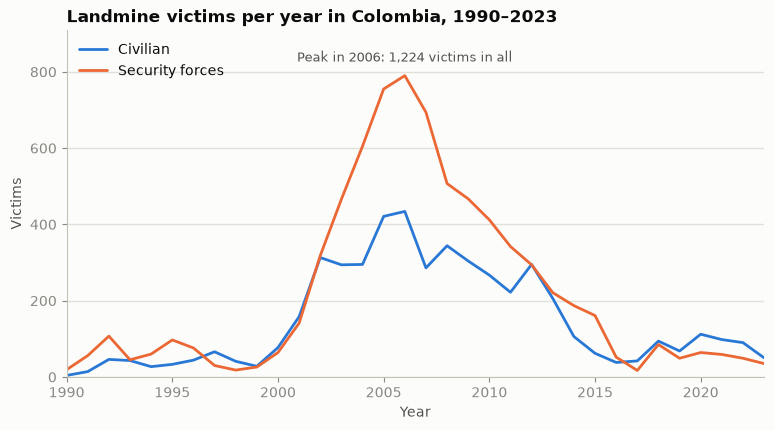

In [20]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for group in ["Civilian", "Security forces"]:
    ax.plot(yearly.index, yearly[group], color=GROUP_COLOURS[group], label=group,
            solid_capstyle="round", solid_joinstyle="round")
peak_year = int(yearly["Total"].idxmax())
ax.annotate(f"Peak in {peak_year}: {yearly.loc[peak_year, 'Total']:,} victims in all",
            xy=(peak_year, yearly.loc[peak_year, "Security forces"]),
            xytext=(0, 8), textcoords="offset points", ha="center", va="bottom",
            color=INK_2, fontsize=9)
ax.set_title("Landmine victims per year in Colombia, 1990–2023")
ax.set_xlabel("Year")
ax.set_ylabel("Victims")
ax.set_ylim(0, yearly[["Civilian", "Security forces"]].to_numpy().max() * 1.15)
ax.set_xlim(yearly.index.min(), yearly.index.max())
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left")
save_fig(fig, "01_victims_per_year.png")
plt.show()

**Interpretation:** Recorded victims rose sharply after 2000, peaked in 2006 at 1,224 (790 from the security forces and 434 civilians), then fell through the following decade to 90 in 2016. Security forces outnumbered civilians in most of the high-casualty years. From 2017 the pattern reversed: civilians outnumbered security forces every year, and in the 2020s they are 63% of victims (section 4.2). The two series are strongly correlated (0.93), but that mostly reflects their shared rise and fall over time, so it says little about any direct link between them.

### 5.2 Share of victims killed

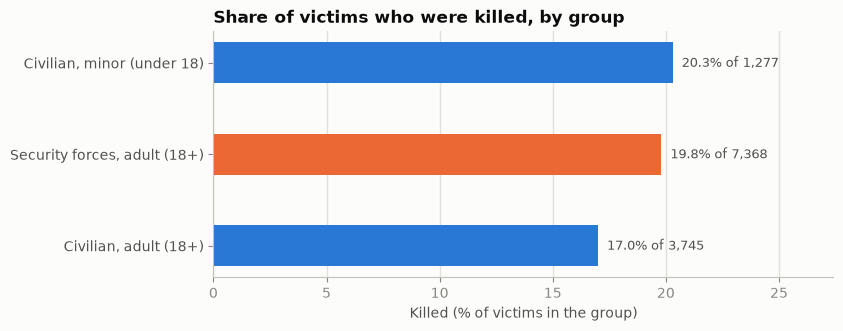

In [21]:
killed = share_killed(df, ["condition", "age_group"]).reset_index()
killed["group"] = killed["condition"] + ", " + killed["age_group"].str.lower()
killed = killed.sort_values("killed %")

fig, ax = plt.subplots(figsize=(8, 3.2))
bars = ax.barh(killed["group"], killed["killed %"], height=0.45,
               color=[GROUP_COLOURS[c] for c in killed["condition"]])
for bar, pct, n in zip(bars, killed["killed %"], killed["victims"]):
    ax.text(bar.get_width() + 0.4, bar.get_y() + bar.get_height() / 2,
            f"{pct:.1f}% of {n:,}", va="center", color=INK_2, fontsize=9)
ax.set_title("Share of victims who were killed, by group")
ax.set_xlabel("Killed (% of victims in the group)")
ax.set_ylabel("")
ax.set_xlim(0, max(killed["killed %"]) * 1.35)
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelcolor=INK_2)
save_fig(fig, "02_share_killed.png")
plt.show()

**Interpretation:** About one victim in five was killed in every group: 20.3% of civilian minors, 19.8% of security-force members and 17.0% of civilian adults. The gaps are a few percentage points, and this notebook does not test whether they are larger than chance would produce; that is the kind of question P2's hypothesis test can answer. All 1,277 minors are civilians; no security-force victim is recorded as a minor.

### 5.3 What civilians were doing

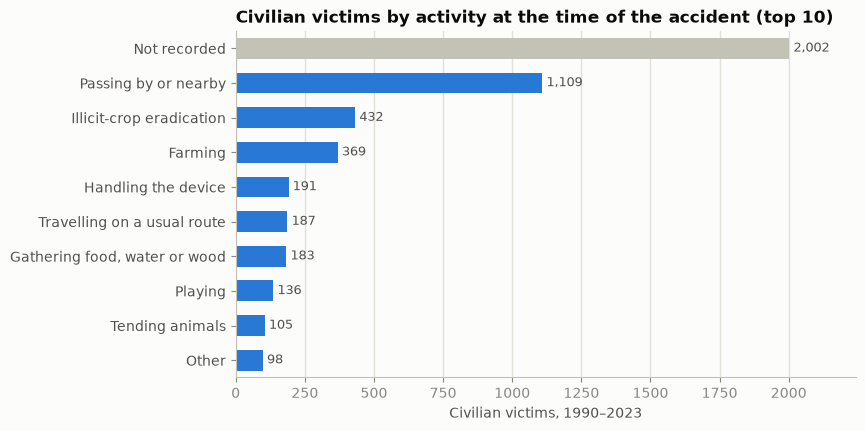

In [22]:
activity = count_and_share(civilians, "activity")
activity["activity"] = activity["activity"].fillna("Not recorded")
top = activity.head(10).sort_values("victims", ascending=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
palette = {a: (NOT_RECORDED if a == "Not recorded" else GROUP_COLOURS["Civilian"])
           for a in top["activity"]}
sns.barplot(data=top, x="victims", y="activity", hue="activity", palette=palette,
            legend=False, ax=ax, width=0.6, saturation=1)
for patch, value in zip(ax.patches, top["victims"]):
    ax.text(patch.get_width() + 15, patch.get_y() + patch.get_height() / 2,
            f"{value:,}", va="center", color=INK_2, fontsize=9)
ax.set_title("Civilian victims by activity at the time of the accident (top 10)")
ax.set_xlabel("Civilian victims, 1990–2023")
ax.set_ylabel("")
ax.set_xlim(0, top["victims"].max() * 1.12)
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelcolor=INK_2)
save_fig(fig, "03_civilian_activity.png")
plt.show()

**Interpretation:** The activity at the time of the accident is not recorded for 40% of civilian victims (2,002 of 5,022), so every share here describes an incomplete picture. Among recorded activities, passing by or being nearby is by far the most common (1,109 victims), followed by illicit-crop eradication (432) and farming (369); handling the device (191) comes fourth. Inference: most recorded civilian accidents happened during ordinary movement and work on the land, which is the exposure that land release and risk education aim to reduce.

### 5.4 Departments with the most victims

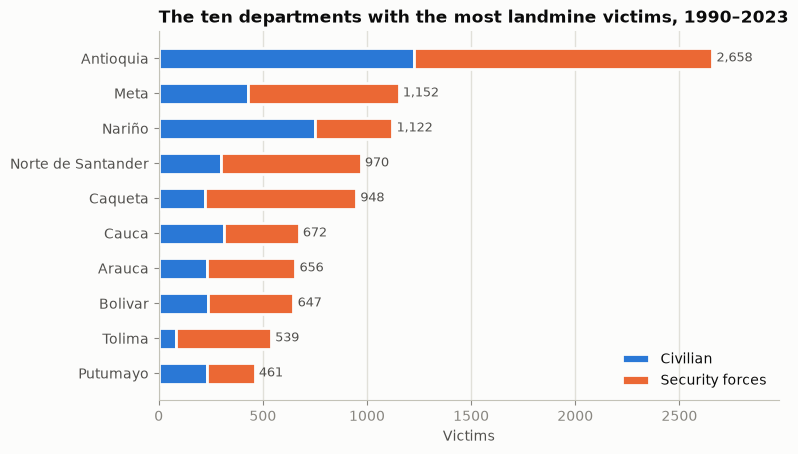

In [23]:
dept = df.groupby(["department", "condition"]).size().unstack(fill_value=0)
dept["Total"] = dept.sum(axis=1)
top_dept = dept.sort_values("Total").tail(10)

fig, ax = plt.subplots(figsize=(8, 4.8))
left = np.zeros(len(top_dept))
for group in ["Civilian", "Security forces"]:
    ax.barh(top_dept.index.str.title().str.replace(" De ", " de "), top_dept[group], left=left, height=0.6,
            color=GROUP_COLOURS[group], label=group, edgecolor=SURFACE, linewidth=2)
    left += top_dept[group].to_numpy()
for y, total in enumerate(top_dept["Total"]):
    ax.text(total + 20, y, f"{total:,}", va="center", color=INK_2, fontsize=9)
ax.set_title("The ten departments with the most landmine victims, 1990–2023")
ax.set_xlabel("Victims")
ax.set_ylabel("")
ax.set_xlim(0, top_dept["Total"].max() * 1.12)
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelcolor=INK_2)
ax.legend(loc="lower right")
save_fig(fig, "04_top_departments.png")
plt.show()

**Interpretation:** Antioquia alone has 2,658 recorded victims, 21.5% of the national total and more than twice the next department, Meta (1,152). The mix varies: most victims in Nariño (67%) and about half in Putumayo (51%) were civilians, while in Tolima (15%), Caquetá (23%) and Norte de Santander (31%) most were from the security forces (table in section 4.2). Inference: these totals reflect where the security forces operated and how completely accidents were reported, as well as where contamination lies.

## 6. Summary

**What the data shows.** The register holds 12,390 victims from 1990 to 2023. Security forces account for 59.5% of them and civilians for 40.5%; 19.0% of all victims were killed; 10.3% were minors, all of them civilians; and 98.0% of accidents happened in rural areas. Victims peaked in 2006 at 1,224 and have stayed below 200 a year since 2016. Since 2017 civilians have outnumbered security forces every year, rising to 63% of victims in the 2020s. Antioquia accounts for about a fifth of all victims.

**Assumptions.** Each row is one victim, so rows that repeat are kept as separate people. The swapped column labels were corrected from their values. The ethnic-group value `no` is read as "none or not recorded". The merged activity categories (crop eradication and security-force duties) are each treated as one activity.

**Limitations.** The activity is missing for 40% of civilian victims and the place type for 92% of all victims, so those breakdowns are partial. The file has no event identifier, so victims cannot be grouped into accidents, and location is known only to the municipality. The figures count recorded victims: under-reporting, especially in remote areas and earlier years, may affect them but cannot be measured from this file. The analysis is descriptive, with no statistical tests and no causal claims.

**Surprises and open questions.** Three published column labels did not match their values. Almost a third of the rows (31%) repeat another row exactly, and a routine de-duplication would have removed 37.4% of security-force victims but only 22.0% of civilians, quietly changing every comparison between the two groups. The shift towards civilian victims after 2017 is the clearest pattern in the data; explaining it needs sources beyond this file.

**Next.** The cleaning functions are written so they can be reused on the events table in P2.